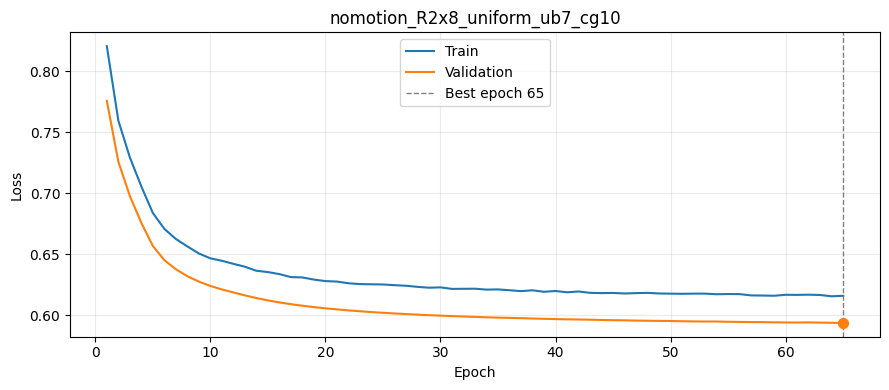

  Epochs trained : 65
  Best epoch     : 65  (val loss 0.593657)
  Latest val     : 0.593657
  Lambda         : 0.006588
  CG_Iter        : 10
  Unrolls        : 7
  Data           : /autofs/space/daisy_002/users/unay/2026_09_23_bay5_invivo_spiral_qalas_vnav_motion_2/spiral_qalas_nomotion_R2x8_mc_3d_moco_input.h5
  Output         : /autofs/space/daisy_002/users/unay/2026_09_23_bay5_invivo_spiral_qalas_vnav_motion_2/reconstructions/ZS_SSL_nomotion_R2x8_uniform_3D


In [ ]:
from pathlib import Path

import numpy as np
import matplotlib.pyplot as plt
import torch

# ═══════════════════════════════════════════════════════════════════════
# CONFIG — R=2x1, No MoCo, full 3D
# ═══════════════════════════════════════════════════════════════════════

MODEL_DIR = Path(
    "saved_models/nomotion_R2x1_nomoco_ub7_cg10"
)

CHECKPOINT = "best.pth"

DATA_PATH = Path(
    "/autofs/space/daisy_002/users/unay/2026_09_23_bay5_invivo_spiral_qalas_vnav_motion_2/"
    "spiral_qalas_nomotion_R2x1_mc_3d_nomoco_input.h5"
)

OUTPUT_DIR = Path(
    "/autofs/space/daisy_002/users/unay/2026_09_23_bay5_invivo_spiral_qalas_vnav_motion_2/"
    "reconstructions/ZS_SSL_nomotion_R2x1_nomoco_3D"
)

SLICE_Z = None

NIFTI_AFFINE = np.eye(4, dtype=np.float64)
# ═══════════════════════════════════════════════════════════════════════

OUTPUT_DIR.mkdir(
    parents=True,
    exist_ok=True,
)

ckpt = torch.load(
    MODEL_DIR / CHECKPOINT,
    map_location="cpu",
)

train_loss = np.array(
    ckpt["train_loss_history"],
    dtype=np.float64,
)

val_loss = np.array(
    ckpt["val_loss_history"],
    dtype=np.float64,
)

epochs = np.arange(
    1,
    len(train_loss) + 1,
)

best_epoch = int(
    np.argmin(val_loss)
) + 1

best_val = float(
    val_loss[best_epoch - 1]
)

fig, ax = plt.subplots(
    figsize=(9, 4)
)

ax.plot(
    epochs,
    train_loss,
    label="Train",
    lw=1.5,
)

ax.plot(
    epochs,
    val_loss,
    label="Validation",
    lw=1.5,
)

ax.axvline(
    best_epoch,
    color="gray",
    lw=1,
    ls="--",
    label=f"Best epoch {best_epoch}",
)

ax.scatter(
    [best_epoch],
    [best_val],
    zorder=5,
    color="tab:orange",
    s=50,
)

ax.set_xlabel("Epoch")
ax.set_ylabel("Loss")
ax.set_title(MODEL_DIR.name)
ax.legend()
ax.grid(alpha=0.25)

fig.tight_layout()
plt.show()

print(f"  Epochs trained : {int(ckpt['epoch']) + 1}")
print(f"  Best epoch     : {best_epoch}  (val loss {best_val:.6f})")
print(f"  Latest val     : {val_loss[-1]:.6f}")
print(f"  Lambda         : {float(ckpt['model_state']['lam']):.6f}")
print(f"  CG_Iter        : {ckpt['CG_Iter']}")
print(f"  Unrolls        : {ckpt['nb_unroll_blocks']}")
print(f"  Data           : {DATA_PATH}")
print(f"  Output         : {OUTPUT_DIR}")

In [2]:
import gc

import cupy as cp
import h5py
import numpy as np
import torch

from mrinufft import get_operator
from mrinufft.operators import compute_toeplitz_kernel

from models import parser_ops, UnrollNet, utils
import models.data_consistency as ssdu_dc


def trajectory_to_mrinufft(trajectory):

    trajectory = np.asarray(
        trajectory,
        dtype=np.float32,
    )

    trajectory = (
        (
            trajectory
            + np.float32(0.5)
        )
        % np.float32(1.0)
        - np.float32(0.5)
    )

    trajectory = (
        trajectory
        * np.float32(2.0 * np.pi)
    )

    return np.ascontiguousarray(
        trajectory,
        dtype=np.float32,
    )


# ── Cleanup ────────────────────────────────────────────────────────────

for _v in [
    "model",
    "operators",
    "toeplitz_operators",
    "toeplitz_kernels",
    "x",
    "recon",
    "nw_input",
]:

    if _v in globals():
        del globals()[_v]

gc.collect()

torch.cuda.empty_cache()

cp.get_default_memory_pool().free_all_blocks()
cp.get_default_pinned_memory_pool().free_all_blocks()


# ── Device ─────────────────────────────────────────────────────────────

device = torch.device("cuda")

free, total = cp.cuda.runtime.memGetInfo()

print(
    f"GPU  : {torch.cuda.get_device_name(0)}"
)

print(
    f"VRAM : {free/1024**3:.1f} / "
    f"{total/1024**3:.1f} GB free"
)


# ── Load checkpoint state ──────────────────────────────────────────────

state = ckpt["model_state"]

nb_features = int(
    state[
        "regularizer.layer1.0.weight"
    ].shape[0]
)

nb_res_blocks = len(
    {
        int(k.split(".")[3])
        for k in state
        if k.startswith(
            "regularizer.layer2.layers."
        )
        and k.split(".")[3].isdigit()
    }
)

args = parser_ops.get_parser().parse_args([])

args.nb_unroll_blocks = int(
    ckpt["nb_unroll_blocks"]
)

args.CG_Iter = int(
    ckpt["CG_Iter"]
)

args.CG_tol = float(
    ckpt["CG_tol"]
)

args.nb_res_blocks = nb_res_blocks
args.nb_features = nb_features

args.implicit_cg = True


# ── Data ───────────────────────────────────────────────────────────────

with h5py.File(
    DATA_PATH,
    "r",
) as f:

    kspace_raw = (
        f["kspace"][()]
        .astype(np.complex64)
    )

    trajectory = (
        f["trajectory"][()]
        .astype(np.float32)
    )

    sens_maps = (
        f["sens_maps"][()]
        .astype(np.complex64)
    )


if kspace_raw.ndim == 2:
    kspace_raw = kspace_raw[None]

if trajectory.ndim == 2:
    trajectory = trajectory[None]

if sens_maps.ndim == 3:
    sens_maps = sens_maps[:, :, None, :]


ncontrast, n_coils, n_samples = (
    kspace_raw.shape
)

nspatial = trajectory.shape[-1]

nx, ny, nz, _ = sens_maps.shape

image_shape = (
    (nx, ny, nz)
    if nspatial == 3
    else (nx, ny)
)

z = (
    nz // 2
    if SLICE_Z is None
    else SLICE_Z
)


kspace_scale = float(
    ckpt["kspace_scale"]
)

kspace = (
    kspace_raw
    / kspace_scale
).astype(np.complex64)

del kspace_raw
gc.collect()


smaps_op = np.ascontiguousarray(
    np.moveaxis(
        sens_maps
        if nspatial == 3
        else sens_maps[:, :, 0, :],
        -1,
        0,
    ),
    dtype=np.complex64,
)

n_trans = int(
    ckpt["n_trans"]
)

smaps_cached = (
    nspatial == 2
)


args.nrow_GLOB = nx
args.ncol_GLOB = ny
args.nz_GLOB = nz

args.ncoil_GLOB = n_coils
args.ncontrast_GLOB = ncontrast
args.nspatial_GLOB = nspatial


print(
    f"Data : {ncontrast} contrasts, "
    f"{n_coils} coils, "
    f"shape={image_shape}, "
    f"z={z}"
)


# ── Operators ──────────────────────────────────────────────────────────

print("Building operators...")

operators = []
toeplitz_operators = []

for c in range(ncontrast):

    traj_c = trajectory_to_mrinufft(
        trajectory[c]
    )

    traj_t = torch.from_numpy(
        traj_c
    ).to(device)

    # Differentiable NUFFT
    operators.append(

        get_operator(
            "cufinufft",
            wrt_data=True,
        )(
            samples=traj_t,
            shape=image_shape,
            n_coils=n_coils,
            smaps=smaps_op,
            density=False,
            squeeze_dims=False,
            smaps_cached=smaps_cached,
            n_trans=n_trans,
        )

    )

    # Toeplitz SENSE operator
    toeplitz_operators.append(

        get_operator(
            "cufinufft",
            samples=traj_c,
            shape=image_shape,
            n_coils=n_coils,
            smaps=smaps_op,
            density=False,
            squeeze_dims=True,
            smaps_cached=smaps_cached,
            n_trans=n_trans,
        )

    )


# ── Adjoint + Toeplitz kernels ─────────────────────────────────────────

print(
    "Computing adjoint and Toeplitz kernels..."
)

full_mask = np.ones(
    (
        ncontrast,
        n_samples,
    ),
    dtype=np.float32,
)

nw_input = np.empty(
    (
        1,
        ncontrast,
        *image_shape,
    ),
    dtype=np.complex64,
)

for c in range(ncontrast):

    nw_input[0, c] = (
        utils.nufft_sense_adjoint(
            operator=operators[c],
            kspace=kspace[c],
            sample_mask=full_mask[c],
            device=device,
        )
    )


toeplitz_kernels = [
    [None] * ncontrast
]

for c in range(ncontrast):

    traj_c = trajectory_to_mrinufft(
        trajectory[c]
    )

    kern_op = get_operator(
        "cufinufft",
        samples=traj_c,
        shape=image_shape,
        n_coils=1,
        density=False,
        squeeze_dims=True,
        n_trans=1,
    )

    w = cp.asarray(
        full_mask[c],
        dtype=cp.complex64,
    )

    toeplitz_kernels[0][c] = (
        cp.asnumpy(
            compute_toeplitz_kernel(
                kern_op,
                weights=w,
            )
        )
    )

    del w, kern_op

    cp.get_default_memory_pool().free_all_blocks()


# ── Model ──────────────────────────────────────────────────────────────

model = UnrollNet.UnrolledNet(
    args=args,
    operators=operators,
    toeplitz_operators=toeplitz_operators,
    toeplitz_kernels=toeplitz_kernels,
    device=device,
    ndim=nspatial,
).to(device)

model.load_state_dict(
    state
)

model.eval()

lam = (
    model.lam
    .detach()
    .cpu()
    .item()
)

print(
    f"Model ready — λ={lam:.4f}"
)

print(
    "Run Cell 3 to reconstruct."
)

GPU  : NVIDIA RTX A6000
VRAM : 47.2 / 47.5 GB free
Data : 5 contrasts, 16 coils, shape=(220, 220, 144), z=72
Building operators...
Computing adjoint and Toeplitz kernels...
Model ready — λ=0.0066
Run Cell 3 to reconstruct.


In [3]:
import time

# ── Prepare network input ──────────────────────────────────────────────

nw_input_real = (
    utils.complex2real(
        nw_input
    )
    .astype(np.float32)
)

x = torch.from_numpy(
    nw_input_real
).to(device)

perm = (
    [0, 1, x.ndim - 1]
    + list(
        range(
            2,
            x.ndim - 1,
        )
    )
)

x = (
    x.permute(*perm)
    .reshape(
        1,
        2 * ncontrast,
        *image_shape,
    )
)

input_x = x.clone()

full_mask_t = torch.from_numpy(
    full_mask[None]
).to(device)

kernel_indices = torch.zeros(
    1,
    dtype=torch.long,
    device=device,
)

active_kernels = (
    model._get_active_kernels(
        kernel_indices
    )
)


# ── Reconstruction ─────────────────────────────────────────────────────

t0 = time.perf_counter()

with torch.inference_mode():

    for u in range(
        args.nb_unroll_blocks
    ):

        # ResNet
        regularized = (
            model.regularizer(x)
        )

        # RHS
        rhs = (
            input_x
            + model.lam * regularized
        )

        del regularized

        # Data consistency
        outs = []

        for c in range(
            ncontrast
        ):

            kernels_c = (
                {
                    ki:
                    active_kernels[ki][c]

                    for ki
                    in active_kernels
                }

                if active_kernels
                is not None

                else None
            )

            x_c = ssdu_dc.dc_block(
                rhs=rhs[
                    :,
                    2*c:2*c+2,
                ],
                operator=operators[c],
                mask=full_mask_t[
                    :,
                    c,
                    :,
                ],
                mu=model.lam,
                args=args,
                toeplitz_operator=
                    toeplitz_operators[c],
                toeplitz_kernels=
                    kernels_c,
                kernel_indices=
                    kernel_indices,
                x0=x[
                    :,
                    2*c:2*c+2,
                ],
            )

            outs.append(
                x_c
            )

        del rhs

        x = torch.cat(
            outs,
            dim=1,
        )

        del outs

        torch.cuda.empty_cache()

        cp.get_default_memory_pool().free_all_blocks()

        print(
            f"Unroll "
            f"{u+1}/"
            f"{args.nb_unroll_blocks}"
        )

    # Final ResNet pass
    x = model.regularizer(
        x
    )


# ── Convert result ─────────────────────────────────────────────────────

recon = (
    x.cpu()
    .numpy()
)

print(
    f"Inference: "
    f"{time.perf_counter() - t0:.1f} s"
)


# ── Magnitude images ───────────────────────────────────────────────────

recon_mag = np.stack(
    [
        np.abs(
            (
                recon[0, 2*c]
                + 1j * recon[0, 2*c + 1]
            )
        )

        for c in range(
            ncontrast
        )
    ]
)

print(
    "recon_mag shape:",
    recon_mag.shape,
)

del (
    x,
    input_x,
    full_mask_t,
    kernel_indices,
)

torch.cuda.empty_cache()

Unroll 1/7
Unroll 2/7
Unroll 3/7
Unroll 4/7
Unroll 5/7
Unroll 6/7
Unroll 7/7
Inference: 119.3 s
recon_mag shape: (5, 220, 220, 144)


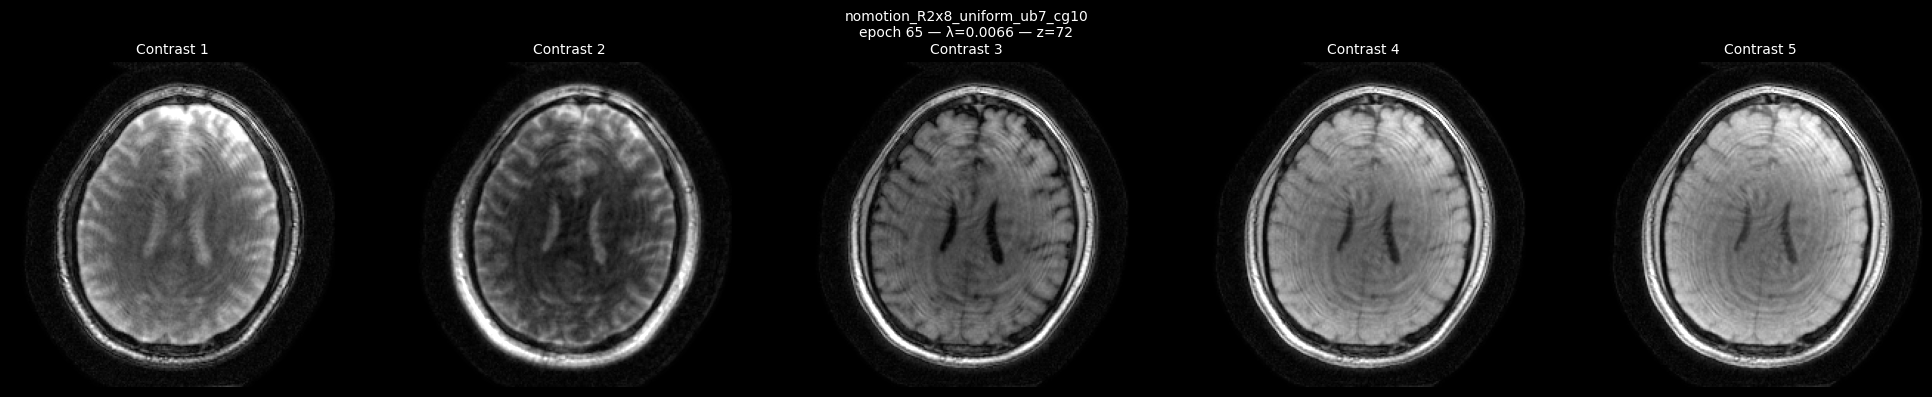

In [4]:
fig, axes = plt.subplots(
    1,
    ncontrast,
    figsize=(
        4 * ncontrast,
        4,
    ),
    facecolor="black",
)

if ncontrast == 1:
    axes = [axes]


for c, ax in enumerate(
    axes
):

    if nspatial == 3:

        img = (
            recon_mag[
                c,
                :,
                :,
                z,
            ].T
        )

    else:

        img = (
            recon_mag[
                c,
                :,
                :,
            ].T
        )

    img = np.rot90(
        img,
        k=2,
    )

    ax.imshow(
        img,
        cmap="gray",
        origin="lower",
        vmin=np.percentile(
            img,
            0.5,
        ),
        vmax=np.percentile(
            img,
            99.5,
        ),
    )

    ax.set_title(
        f"Contrast {c+1}",
        color="white",
        fontsize=10,
    )

    ax.axis("off")
    ax.set_facecolor("black")


epoch = (
    int(ckpt["epoch"])
    + 1
)

title = (
    f"{MODEL_DIR.name}\n"
    f"epoch {epoch} — "
    f"λ={lam:.4f}"
)

if nspatial == 3:

    title += (
        f" — z={z}"
    )


fig.suptitle(
    title,
    color="white",
    fontsize=10,
)

fig.patch.set_facecolor(
    "black"
)

plt.tight_layout()
plt.show()

In [5]:
import nibabel as nib
import numpy as np

# ── Make sure output directory exists ──────────────────────────────────

OUTPUT_DIR.mkdir(
    parents=True,
    exist_ok=True,
)

# ── Put contrast dimension last ────────────────────────────────────────
#
# recon_mag = [contrast, x, y]
# QALAS_vol = [x, y, contrast]
#

QALAS_vol = np.moveaxis(
    recon_mag,
    0,
    -1,
).astype(np.float32)

print(
    "QALAS_vol shape:",
    QALAS_vol.shape,
)

# ── Save combined QALAS NIfTI ──────────────────────────────────────────

nii_file = (
    OUTPUT_DIR
    / "QALAS_recon.nii.gz"
)

nib.save(
    nib.Nifti1Image(
        QALAS_vol,
        NIFTI_AFFINE,
    ),
    nii_file,
)

print(
    f"\nSaved:\n{nii_file}"
)

QALAS_vol shape: (220, 220, 144, 5)

Saved:
/autofs/space/daisy_002/users/unay/2026_09_23_bay5_invivo_spiral_qalas_vnav_motion_2/reconstructions/ZS_SSL_nomotion_R2x8_uniform_3D/QALAS_recon.nii.gz
